# E-Commerce Sales & Customer Analytics — Business Insights

## Project Objective

The objective of this analysis is to identify key business insights from e-commerce sales data by analyzing sales, profitability, customer behavior, product performance, regional performance, sales channels, payment methods, shipping methods, discounts, and monthly trends. The analysis will help understand business performance, identify important patterns and areas of improvement, and support data-driven business decision-making.


## Project Data Scope

* **Dataset:** E-Commerce Sales & Customer Analytics
* **Final Records:** 4,961 orders
* **Columns:** 17
* **Customers:** 800 unique customers
* **Products:** 25 unique products
* **Categories:** 5 product categories
* **Regions:** 4 regions
* **Sales Channels:** Marketplace, Mobile App, Website
* **Payment Methods:** Cash on Delivery, Credit Card, Debit Card, Net Banking, UPI
* **Customer Types:** New and Returning
* **Shipping Types:** Standard, Express, Same Day
* **Customer Ratings:** 1 to 5
* **Discounts:** 0% to 35%
* **Analysis Period:** Based on the `Order_Date` field in the dataset

The analysis focuses on order-level sales, profit, quantity, customer, product, regional, channel, payment, shipping, discount, and rating information.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load Cleaned Dataset

In [2]:
df = pd.read_csv('Ecommerce_Sales_Analytics_Cleaned.csv')

In [3]:
df.shape

(4961, 18)

In [4]:
df.head(5)

,Order_ID,Order_Date,Customer_ID,City,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Method,Sales_Channel,Customer_Type,Customer_Rating,Shipping_Type,Month
0,ORD100000,2025-04-13,CUST1375,Ahmedabad,West,Electronics,Headphones,3,4908.52,0.00,14725.56,5302.90,Net Banking,Mobile App,Returning,5.0,Express,4
1,ORD100001,2025-12-15,CUST1144,Kolkata,East,Electronics,Tablet,3,29719.29,0.00,89157.87,22571.48,Credit Card,Mobile App,Returning,4.0,Standard,12
2,ORD100002,2025-09-28,CUST1398,Pune,West,Home & Kitchen,Cookware Set,1,10312.62,0.10,9281.36,1133.62,UPI,Mobile App,New,4.0,Standard,9
3,ORD100003,2025-04-17,CUST1037,Lucknow,North,Home & Kitchen,Office Chair,4,17857.59,0.05,67858.84,15913.54,Debit Card,Website,Returning,4.0,Express,4
4,ORD100004,2025-03-13,CUST1228,Bengaluru,South,Fashion,T-Shirt,2,1603.71,0.05,3047.05,452.88,Cash on Delivery,Marketplace,New,4.0,Same Day,3


In [5]:
df.dtypes

Order_ID            object
Order_Date          object
Customer_ID         object
City                object
Region              object
Category            object
Product             object
Quantity             int64
Unit_Price         float64
Discount           float64
Sales              float64
Profit             float64
Payment_Method      object
Sales_Channel       object
Customer_Type       object
Customer_Rating    float64
Shipping_Type       object
Month                int64
dtype: object

## 2. Key Performance Indicators (KPIs)

In [6]:
#Total Sales

df['Sales'].sum()

np.float64(114339453.67)

In [7]:
#Total Profit

df['Profit'].sum()

np.float64(28308132.76)

In [8]:
# Total Orders

df.shape[0]

4961

In [9]:
#Total Quantity sold

df['Quantity'].sum()

np.int64(11560)

In [10]:
#Average Sales per Order

df['Sales'].mean()

np.float64(23047.662501511793)

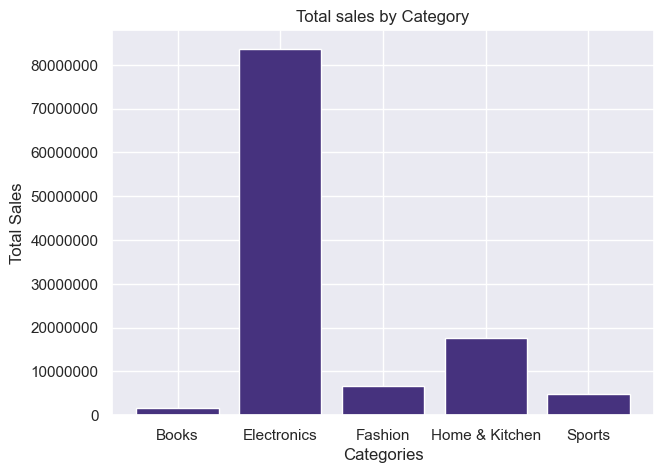

In [11]:
# how much total sales each product category contributes.
sns.set_theme(style='darkgrid', palette='viridis')

total = df.groupby('Category')['Sales'].sum()
total
plt.figure(figsize=(7, 5))
plt.bar(total.index , total.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Categories')
plt.ylabel('Total Sales')
plt.title('Total sales by Category')

plt.show()

- Highest total sales: Electronics
- Lowest total sales: Books

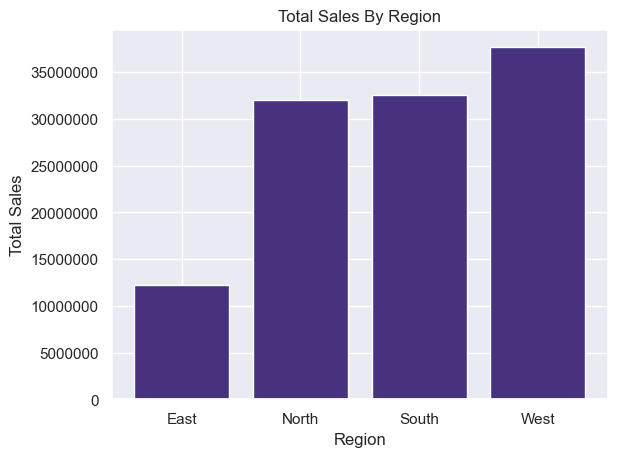

In [12]:
# Which region contributes the highest total sales?

total = df.groupby('Region')['Sales'].sum()
total

plt.bar(total.index, total.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.title('Total Sales By Region')

plt.show()

- Highest-sales region: West
- Lowest-sales region: East

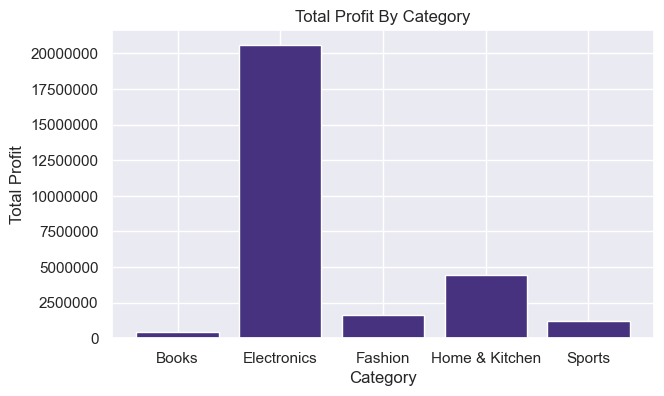

In [13]:
# Which product category generates the highest total profit?

ans = df.groupby('Category')['Profit'].sum()
ans

plt.figure(figsize=(7, 4))
plt.bar(ans.index, ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.title('Total Profit By Category')

plt.show()

- Highest-profit category: Electronics
- Lowest-profit category: Books

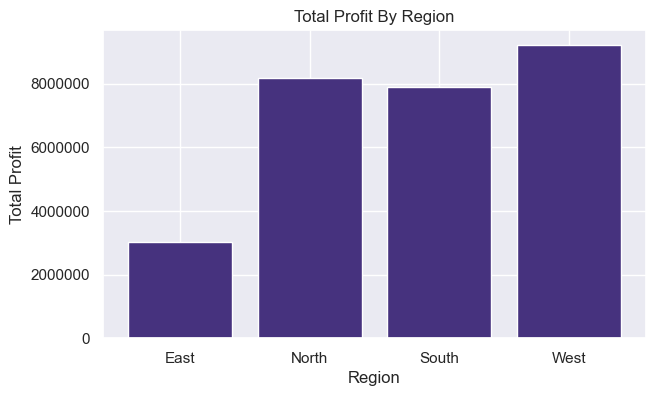

In [14]:
# Which region generates the highest total profit?

ans = df.groupby('Region')['Profit'].sum()
ans

plt.figure(figsize=(7, 4))
plt.bar(ans.index, ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.title('Total Profit By Region')

plt.show()

- Highest-profit region: West
- Lowest-profit region: East

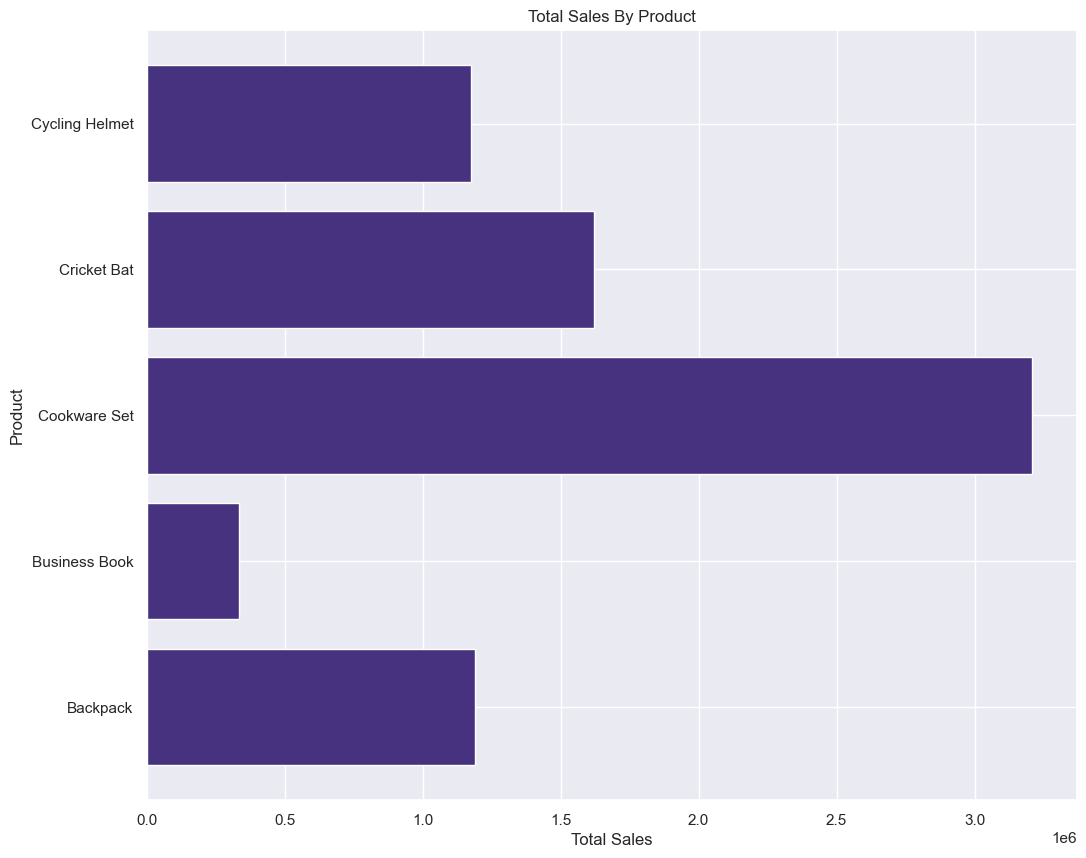

In [15]:
# Which product generates the highest total sales?

ans = df.groupby('Product')['Sales'].sum().head(5)
ans

plt.figure(figsize=(12, 10))

plt.barh(ans.index, ans.values)

plt.xlabel('Total Sales')
plt.ylabel('Product')
plt.title('Total Sales By Product')

plt.show()

- Highest sales: Laptop — ₹36,483,511.51
- Lowest sales: Novel — ₹225,760.67

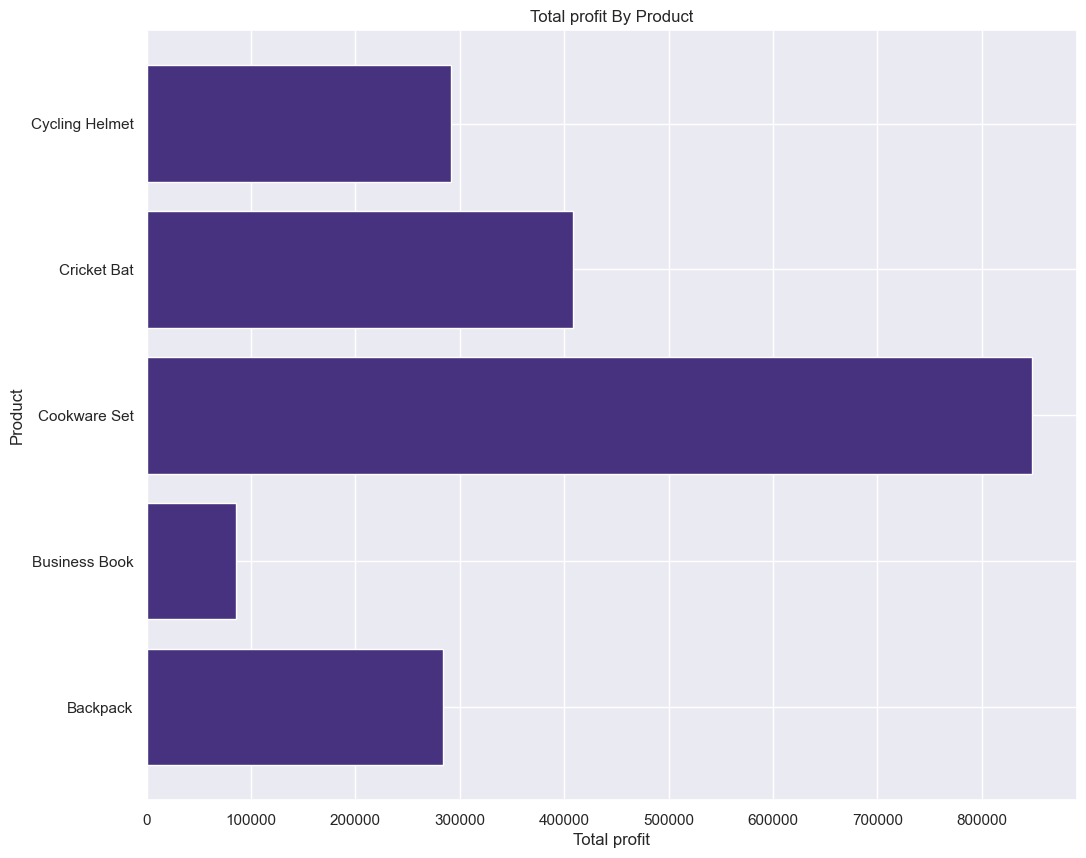

In [92]:
# Which product generates the highest total profit?

ans = df.groupby('Product')['Profit'].sum().head(5)
ans

plt.figure(figsize=(12, 10))

plt.barh(ans.index, ans.values)

plt.xlabel('Total profit')
plt.ylabel('Product')
plt.title('Total profit By Product')

plt.show()

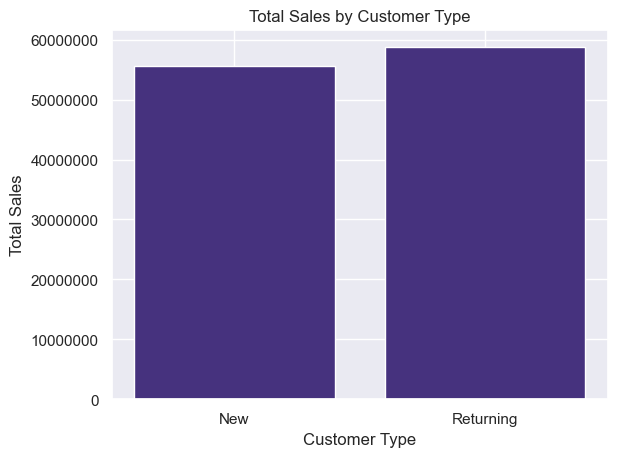

In [16]:
# Which customer type has the highest total sales?
# What are the total sales for both customer types?

ans = df.groupby('Customer_Type')['Sales'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Customer Type')
plt.ylabel('Total Sales')
plt.title('Total Sales by Customer Type')

plt.show()

- New customers: ₹55,584,866.60
- Returning customers: ₹58,754,587.07
- Highest sales: Returning customers

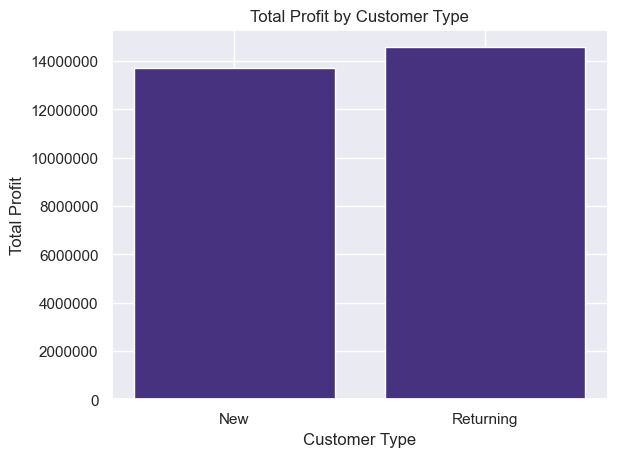

In [17]:
# Which customer type has the highest profit?
# What is the total profit for both customer types?

ans = df.groupby('Customer_Type')['Profit'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Customer Type')
plt.ylabel('Total Profit')
plt.title('Total Profit by Customer Type')

plt.show()

- New customers: ₹13,731,762.62
- Returning customers: ₹14,576,370.14
- Highest Profit: Returning customers

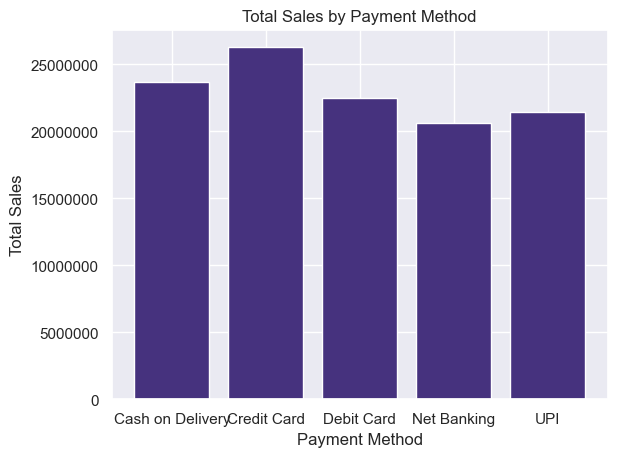

In [18]:
# total sales generated by each Payment Method

ans = df.groupby('Payment_Method')['Sales'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Payment Method')
plt.ylabel('Total Sales')
plt.title('Total Sales by Payment Method')

plt.show()

- Highest sales: Credit Card — ₹26,268,671.64
- Lowest sales: Net Banking — ₹20,576,745.78

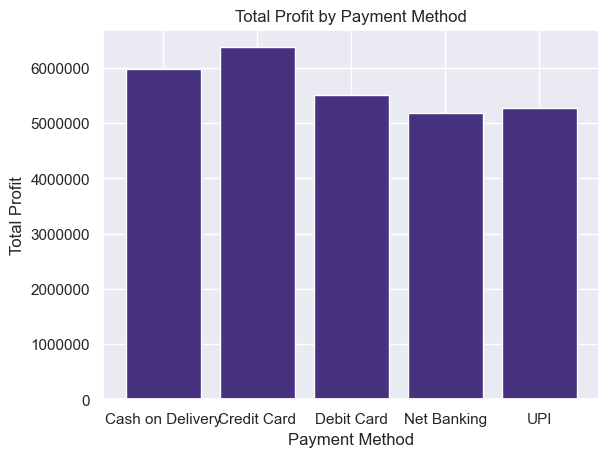

In [19]:
# total Profit for each Payment Method

ans = df.groupby('Payment_Method')['Profit'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Payment Method')
plt.ylabel('Total Profit')
plt.title('Total Profit by Payment Method')

plt.show()

- Highest profit: Credit Card — ₹6,376,393.63
- Lowest profit: Net Banking — ₹5,179,342.77

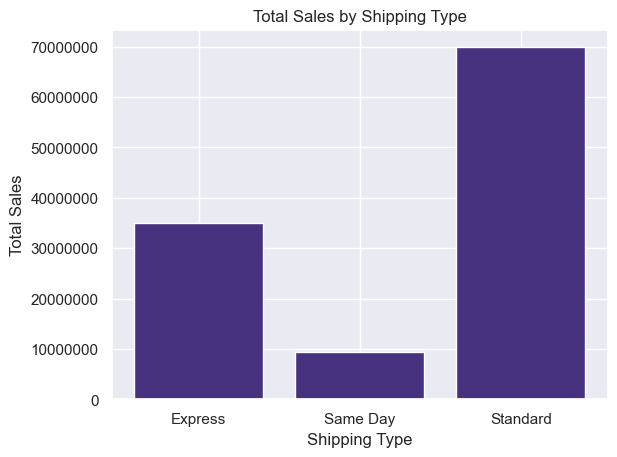

In [20]:
# Total Sales for each Shipping Type

ans = df.groupby('Shipping_Type')['Sales'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Shipping Type')
plt.ylabel('Total Sales')
plt.title('Total Sales by Shipping Type')

plt.show()

- Highest sales: Standard — ₹69,880,699.11
- Lowest sales: Same Day — ₹9,452,696.02

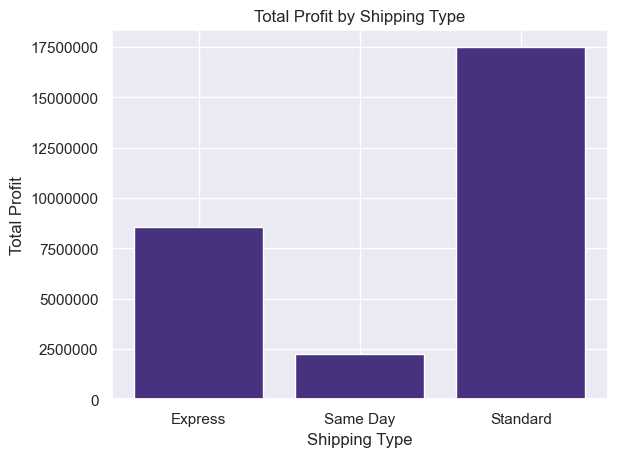

In [21]:
# total Profit for each Shipping Type

ans = df.groupby('Shipping_Type')['Profit'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Shipping Type')
plt.ylabel('Total Profit')
plt.title('Total Profit by Shipping Type')

plt.show()

- Highest profit: Standard
- Lowest profit: Same Day

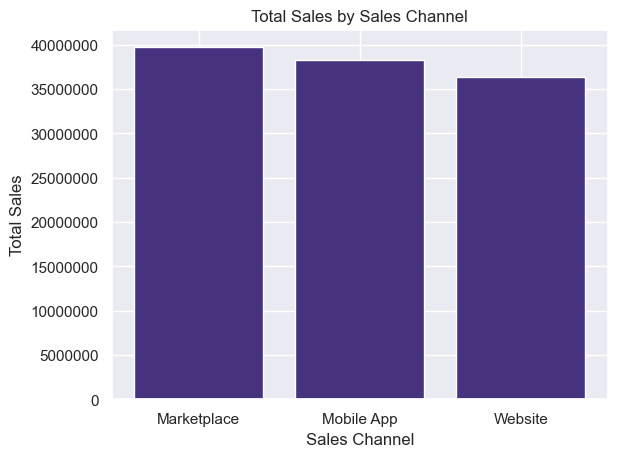

In [22]:
# Total Sales for each Sales_Channel

ans = df.groupby('Sales_Channel')['Sales'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Sales Channel')
plt.ylabel('Total Sales')
plt.title('Total Sales by Sales Channel')

plt.show()

- Highest sales: Marketplace — ₹39,719,821.30
- Lowest sales: Website — ₹36,379,765.68

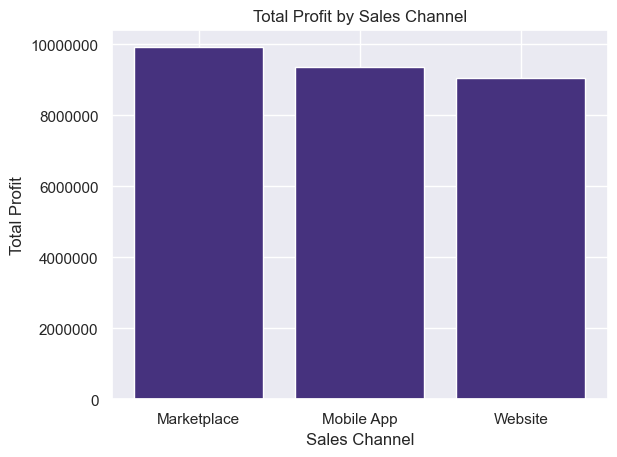

In [23]:
# Total Profit for each Sales_Channel

ans = df.groupby('Sales_Channel')['Profit'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Sales Channel')
plt.ylabel('Total Profit')
plt.title('Total Profit by Sales Channel')

plt.show()

- Highest profit: Marketplace — ₹9,915,967.22
- Lowest profit: Website — ₹9,045,881.44

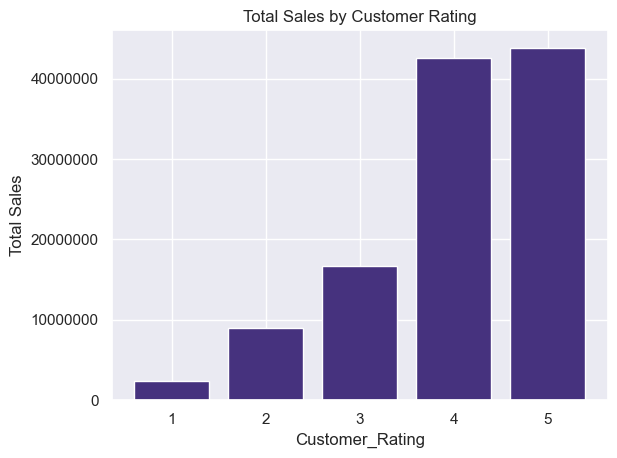

In [24]:
# Total Sales for each Customer_Rating

ans = df.groupby('Customer_Rating')['Sales'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Customer_Rating')
plt.ylabel('Total Sales')
plt.title('Total Sales by Customer Rating')

plt.show()

- Highest sales: Rating 5
- Lowest sales: Rating 1

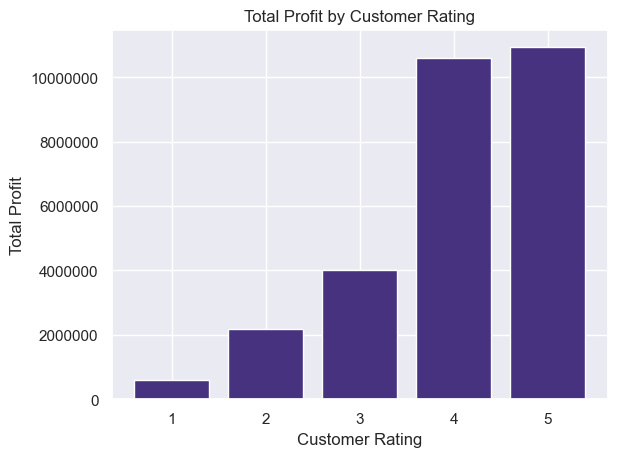

In [25]:
# Total Profit for each Customer_Rating

ans = df.groupby('Customer_Rating')['Profit'].sum()
ans

plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Customer Rating')
plt.ylabel('Total Profit')
plt.title('Total Profit by Customer Rating')

plt.show()

- Highest profit: Rating 5
- Lowest profit: Rating 1

In [26]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'City', 'Region', 'Category',
       'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit',
       'Payment_Method', 'Sales_Channel', 'Customer_Type', 'Customer_Rating',
       'Shipping_Type', 'Month'],
      dtype='object')

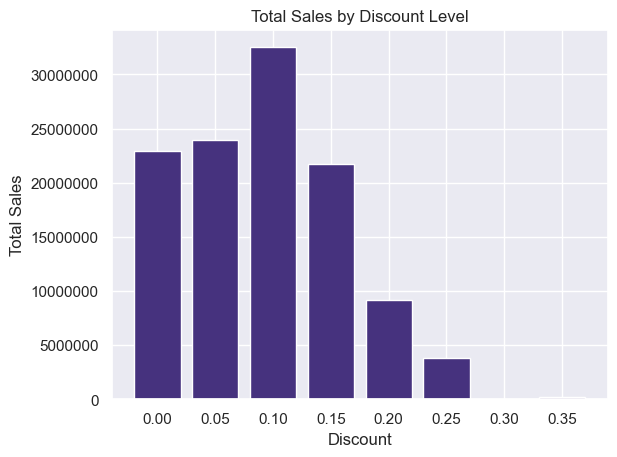

In [27]:
# Total Sales for each Discount level.

ans = df.groupby('Discount')['Sales'].sum()
ans

plt.bar(ans.index , ans.values, width=0.04)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Discount')
plt.ylabel('Total Sales')
plt.title('Total Sales by Discount Level')

plt.show()

- Highest total sales: 10% discount
- Lowest total sales: 35% discount

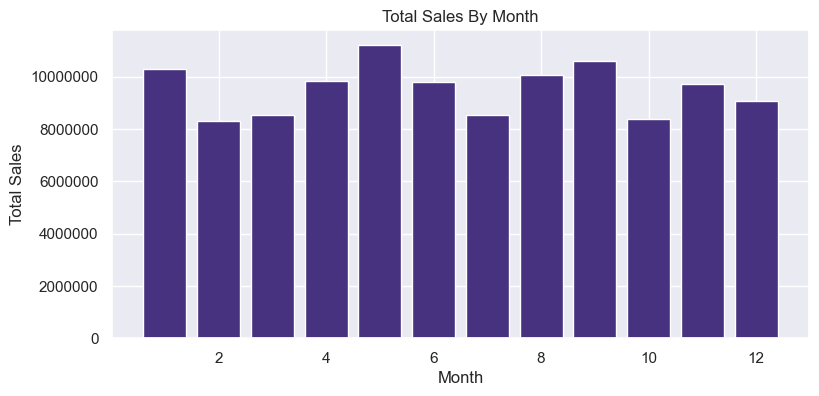

In [28]:
# Total Sales for each Month.

ans = df.groupby('Month')['Sales'].sum()
ans

plt.figure(figsize=(9, 4))
plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Total Sales By Month')

plt.show()

- Highest total sales: May — ₹11,214,322.17
- Lowest total sales: February — ₹8,297,322.67

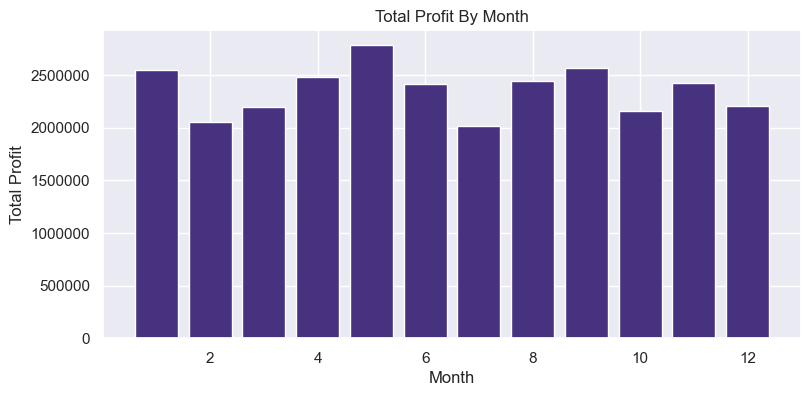

In [29]:
# Total Profit for each Month.
ans = df.groupby('Month')['Profit'].sum()
ans

plt.figure(figsize=(9, 4))
plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.title('Total Profit By Month')

plt.show()

- Highest total profit: May — ₹2,787,819.12
- Lowest total profit: July — ₹2,014,357.55

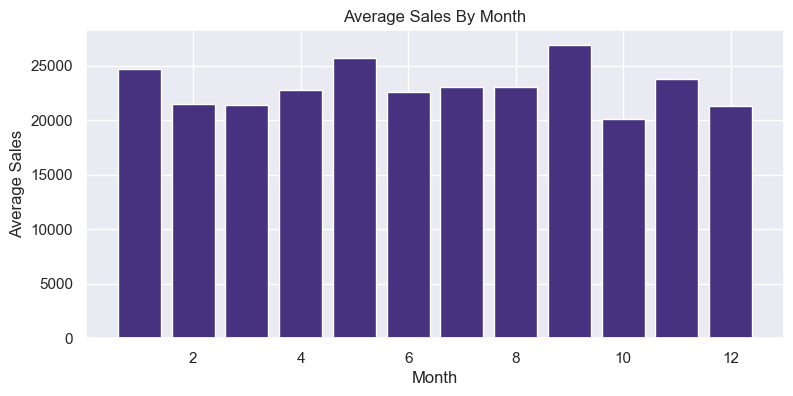

In [30]:
# average Sales for each Month.

ans = df.groupby('Month')['Sales'].mean()
ans

plt.figure(figsize=(9, 4))
plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.title('Average Sales By Month')

plt.show()

- Highest average sales: September — ₹26,892.15
- Lowest average sales: October — ₹20,082.78

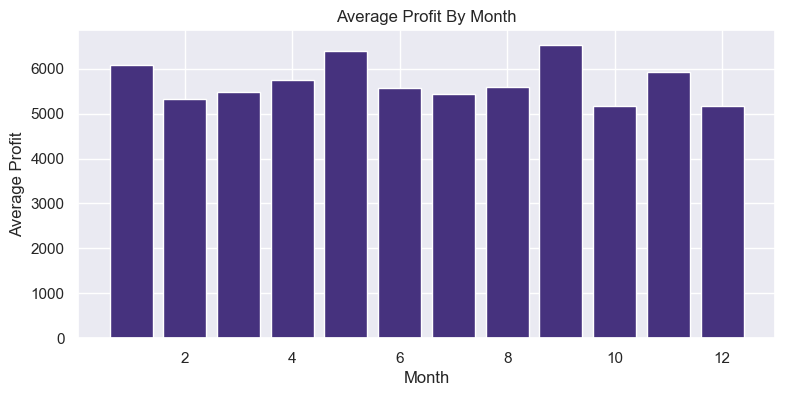

In [31]:
# average Profit for each Month.

ans = df.groupby('Month')['Profit'].mean()
ans

plt.figure(figsize=(9, 4))
plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Month')
plt.ylabel('Average Profit')
plt.title('Average Profit By Month')

plt.show()

- Highest average profit: September — ₹6,528.98
- Lowest average profit: December — ₹5,169.00

In [32]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'City', 'Region', 'Category',
       'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit',
       'Payment_Method', 'Sales_Channel', 'Customer_Type', 'Customer_Rating',
       'Shipping_Type', 'Month'],
      dtype='object')

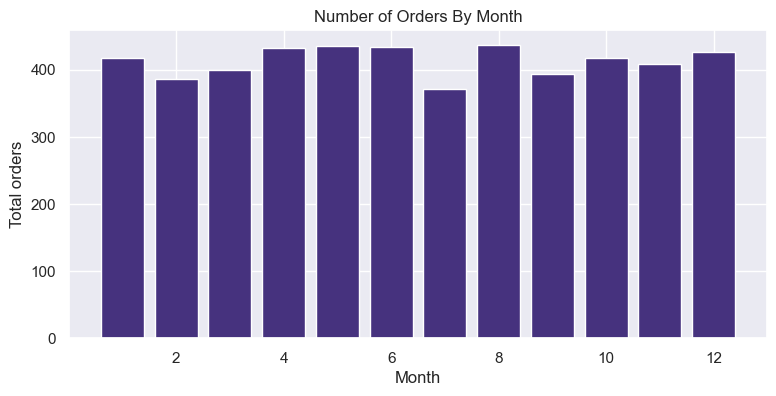

In [33]:
# number of orders for each Month.

ans = df['Month'].value_counts().sort_index()
ans

plt.figure(figsize=(9, 4))
plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Month')
plt.ylabel('Total orders')
plt.title('Number of Orders By Month')

plt.show()

- 📈 Highest orders: August — 437 orders
- 📉 Lowest orders: July — 371 orders

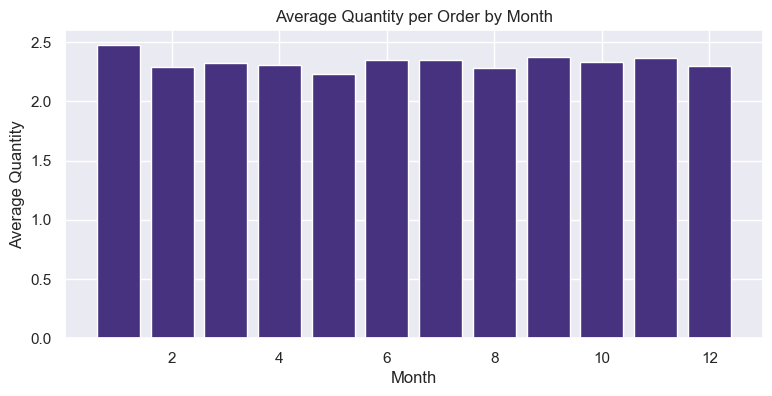

In [34]:
# Average Quantity per Order by Month

ans = df.groupby('Month')['Quantity'].mean()

plt.figure(figsize=(9, 4))
plt.bar(ans.index , ans.values)
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Month')
plt.ylabel('Average Quantity')
plt.title('Average Quantity per Order by Month')

plt.show()

- Highest average quantity per order: January — 2.476077
- Lowest average quantity per order: May — 2.229358

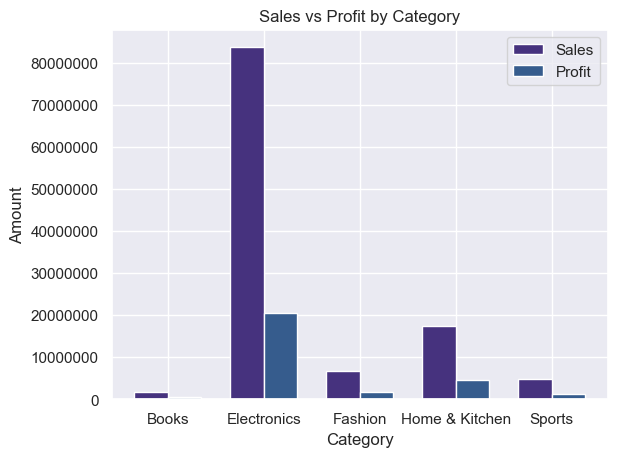

In [35]:
# total Sales and total Profit for each Category.

total_sales = df.groupby('Category')['Sales'].sum()
# print(total_sales)
total_profit = df.groupby('Category')['Profit'].sum()
# print(total_profit)

x = np.arange(len(total_sales))
width = 0.35

plt.bar(x - width/2, total_sales.values, width, label='Sales')
plt.bar(x + width/2, total_profit.values, width, label='Profit')

plt.xlabel('Category')
plt.ylabel('Amount')
plt.title('Sales vs Profit by Category')

plt.xticks(x, total_sales.index)
plt.ticklabel_format(style='plain', axis='y')

plt.legend()
plt.show()

Region
East     12184659.58
North    31981378.09
South    32524863.16
West     37648552.84
Name: Sales, dtype: float64
Region
East     3026867.57
North    8162391.92
South    7903449.11
West     9215424.16
Name: Profit, dtype: float64


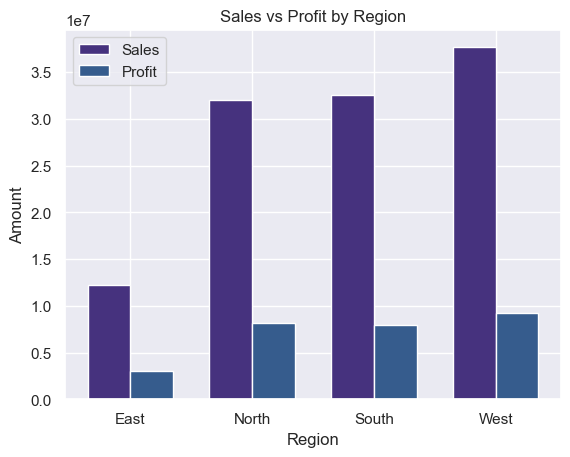

In [36]:
# Sales vs Profit by Region

total_sales = df.groupby('Region')['Sales'].sum()
print(total_sales)
total_profit = df.groupby('Region')['Profit'].sum()
print(total_profit)

x = np.arange(len(total_sales))
width = 0.35

plt.bar(x - width/2, total_sales.values, width, label='Sales')
plt.bar(x + width/2, total_profit.values, width, label='Profit')

plt.xticks(x, total_sales.index)

plt.xlabel('Region')
plt.ylabel('Amount')
plt.title('Sales vs Profit by Region')
plt.legend()

plt.show()

- Highest Sales: West — ₹37,648,552.84
- Lowest Sales: East — ₹12,184,659.58
- Highest Profit: West — ₹9,215,424.16
- Lowest Profit: East — ₹3,026,867.57

Customer_Type
New          55584866.60
Returning    58754587.07
Name: Sales, dtype: float64
Customer_Type
New          13731762.62
Returning    14576370.14
Name: Profit, dtype: float64


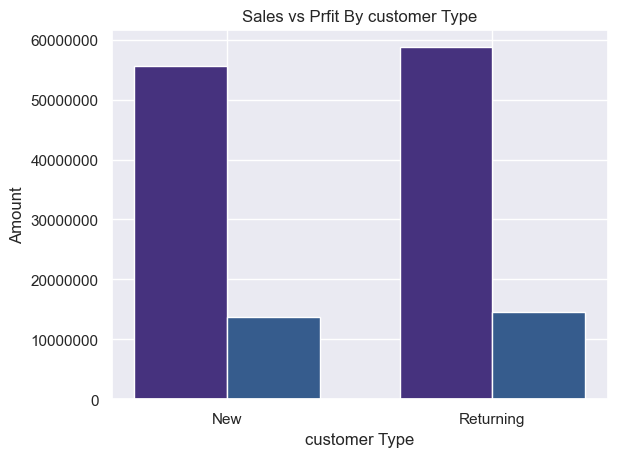

In [37]:
# Compare Sales and Profit by Customer Type

total_Sales = df.groupby('Customer_Type')['Sales'].sum()
print(total_Sales)
total_profit = df.groupby('Customer_Type')['Profit'].sum()
print(total_profit)

x = np.arange(len(total_Sales))
width = 0.35

plt.bar(x-width/2 , total_Sales.values, width, label='Sales')
plt.bar(x+width/2 , total_profit.values, width, label='Profit')
plt.xticks(x, total_Sales.index)

plt.xlabel('customer Type')
plt.ylabel('Amount')
plt.title('Sales vs Prfit By customer Type')
plt.ticklabel_format(style='plain', axis='y')

plt.show()

- Highest Sales: Returning customers → ₹58,754,587.07
- Highest Profit: Returning customers → ₹14,576,370.14

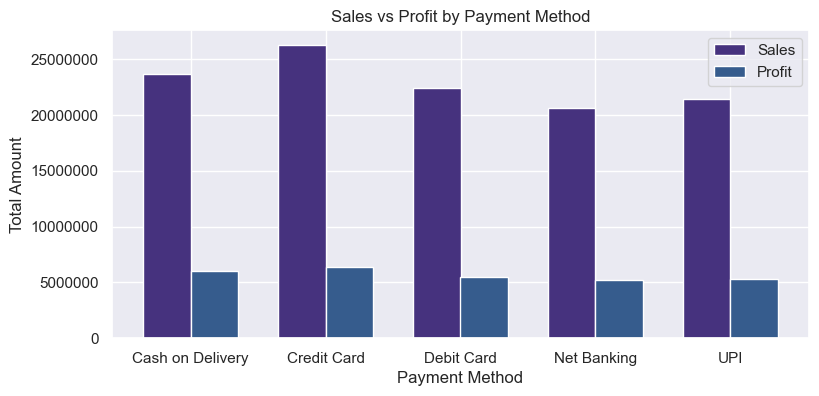

In [38]:
# Compare Sales and Profit by Payment Method using a grouped bar chart.

total_sales = df.groupby('Payment_Method')['Sales'].sum()
total_profit = df.groupby('Payment_Method')['Profit'].sum()


plt.figure(figsize=(9, 4) , dpi=100)
x = np.arange(len(total_sales))
width = 0.35

plt.bar(x-width/2, total_sales.values, width, label='Sales')
plt.bar(x+width/2, total_profit.values, width, label='Profit')
plt.xticks(x, total_sales.index)
plt.ticklabel_format(style='plain', axis='y')

plt.xlabel('Payment Method')
plt.ylabel('Total Amount')
plt.title('Sales vs Profit by Payment Method')
plt.legend()

plt.show()

- Highest → Credit Card: ₹26,268,671.64
- Lowest → Net Banking: ₹20,576,745.78- 

Shipping_Type
Express     35006058.54
Same Day     9452696.02
Standard    69880699.11
Name: Sales, dtype: float64
Shipping_Type
Express      8556480.31
Same Day     2260682.86
Standard    17490969.59
Name: Profit, dtype: float64


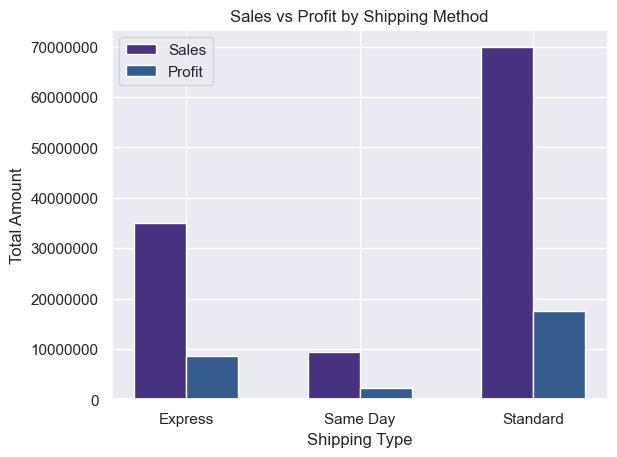

In [39]:
# Compare Sales and Profit by Shipping_Type using a grouped bar chart.

total_sales = df.groupby('Shipping_Type')['Sales'].sum()
print(total_sales)
total_profit = df.groupby('Shipping_Type')['Profit'].sum()
print(total_profit)

x= np.arange(len(total_sales))
width = 0.3

plt.bar(x-width/2, total_sales.values, width, label='Sales')
plt.bar(x+width/2, total_profit.values, width, label='Profit')
plt.xticks(x, total_sales.index)
plt.legend()
plt.ticklabel_format(style='plain', axis='y')

plt.xlabel('Shipping Type')
plt.ylabel('Total Amount')
plt.title('Sales vs Profit by Shipping Method')

plt.show()

- Sales:

Highest → Standard: ₹69,880,699.11
Lowest → Same Day: ₹9,452,696.02

- Profit:

Highest → Standard: ₹17,490,969.59
Lowest → Same Day: ₹2,260,682.86

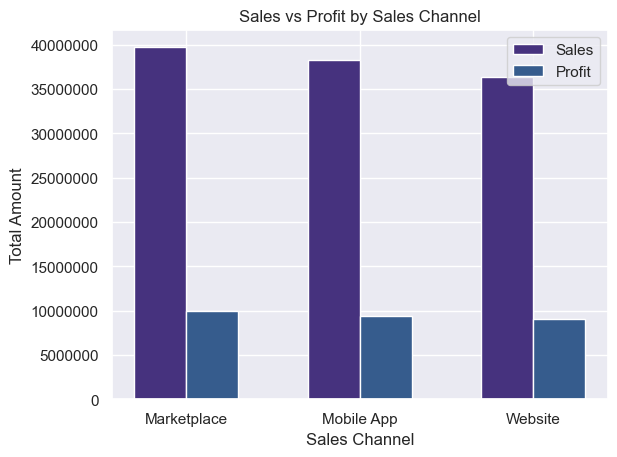

In [40]:
# Compare Sales and Profit by Sales Channel using a grouped bar chart.

total_sales = df.groupby('Sales_Channel')['Sales'].sum()
# print(total_sales)
total_profit = df.groupby('Sales_Channel')['Profit'].sum()
# print(total_profit)

x= np.arange(len(total_sales))
width = 0.3

plt.bar(x-width/2, total_sales.values, width, label='Sales')
plt.bar(x+width/2, total_profit.values, width, label='Profit')
plt.xticks(x, total_sales.index)
plt.legend()
plt.ticklabel_format(style='plain', axis='y')

plt.xlabel('Sales Channel')
plt.ylabel('Total Amount')
plt.title('Sales vs Profit by Sales Channel')

plt.show()

Customer_Rating
1.0     2380786.64
2.0     8922569.69
3.0    16671648.45
4.0    42539317.18
5.0    43825131.71
Name: Sales, dtype: float64
Customer_Rating
1.0      587313.03
2.0     2194440.27
3.0     4011161.36
4.0    10583580.39
5.0    10931637.71
Name: Profit, dtype: float64


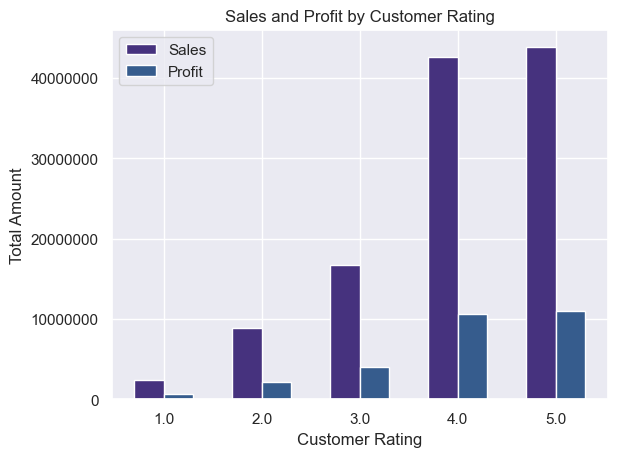

In [41]:
# Compare Sales and Profit by Customer_Rating using a grouped bar chart.

total_sales = df.groupby('Customer_Rating')['Sales'].sum()
print(total_sales)
total_profit = df.groupby('Customer_Rating')['Profit'].sum()
print(total_profit)

x = np.arange(len(total_sales))
width = 0.3

plt.bar(x-width/2, total_sales.values, width, label='Sales')
plt.bar(x+width/2, total_profit.values, width, label='Profit')

plt.xticks(x, total_sales.index)
plt.ticklabel_format(style='plain', axis='y')
plt.legend()
plt.xlabel('Customer Rating')
plt.ylabel('Total Amount')
plt.title('Sales and Profit by Customer Rating')

plt.show()

- Rating 5 has the highest Sales and Profit.
- Rating 1 has the lowest Sales and Profit.
- Sales and Profit both increase as the Customer Rating increases.

- Highest Sales: Laptop → ₹36,483,511.51
- Highest Profit: Laptop → ₹9,034,777.70
- Lowest Sales: Novel → ₹225,760.67
- Lowest Profit: Novel → ₹55,696.90

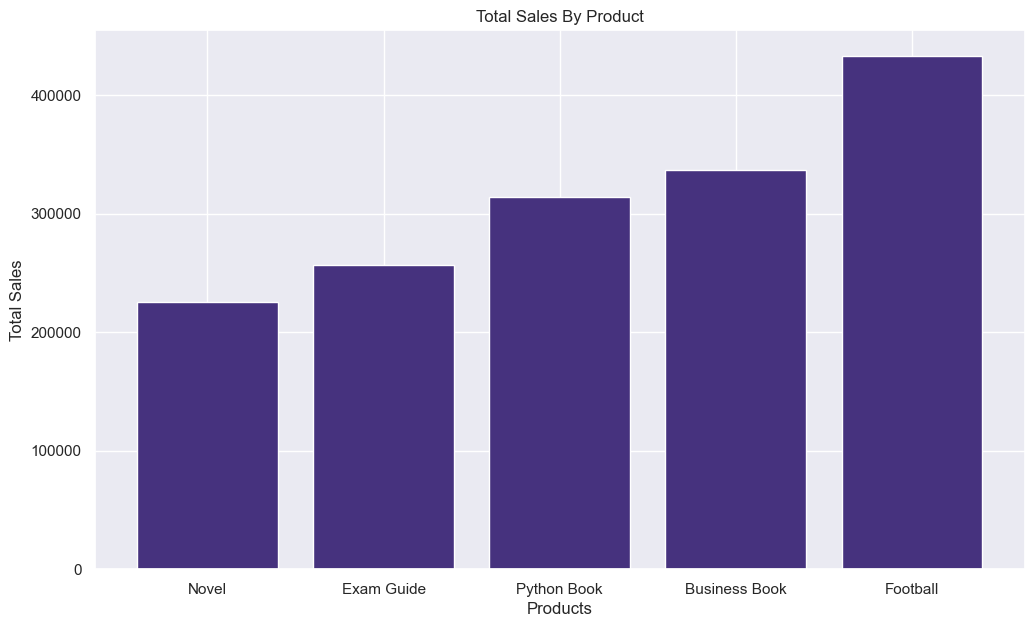

In [45]:
# Find the Bottom 5 Products by Total Sales and create a bar chart showing their Sales.

bottom_Products = df.groupby('Product')['Sales'].sum().sort_values(ascending=True).head(5)
# print(top_Products)

plt.figure(figsize=(12, 7))
plt.bar(bottom_Products.index , bottom_Products.values)
plt.ticklabel_format(style='plain', axis='y')

plt.xlabel('Products')
plt.ylabel('Total Sales')
plt.title('Total Sales By Product')

plt.show()

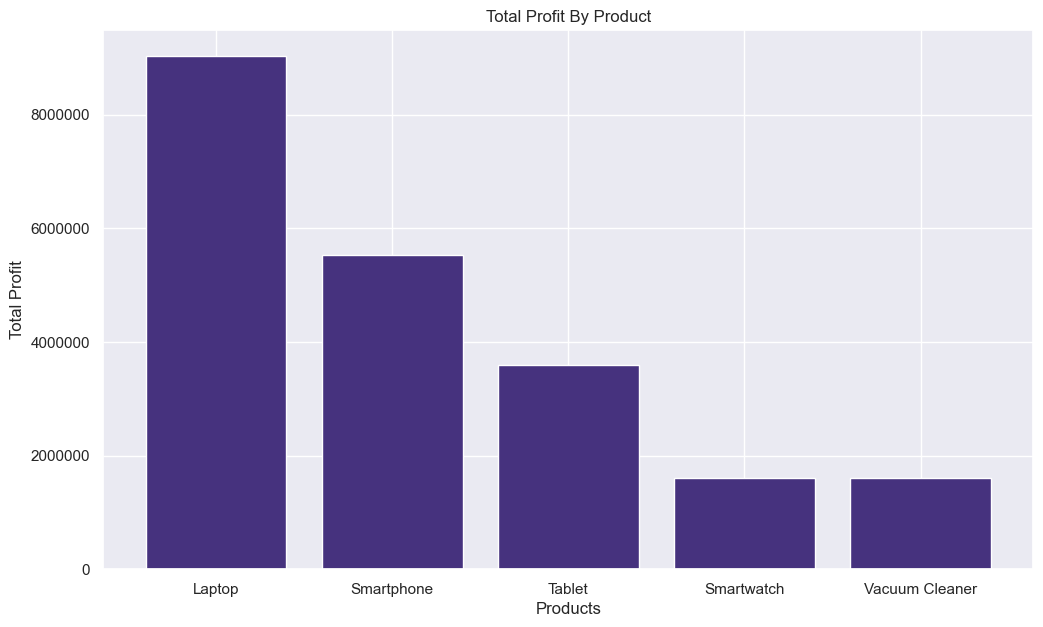

In [46]:
# Find the Top 5 Products by Total Profit and create a bar chart showing their Profit.

top_Products = df.groupby('Product')['Profit'].sum().sort_values(ascending=False).head(5)
# print(top_Products)

plt.figure(figsize=(12, 7))
plt.bar(top_Products.index , top_Products.values)
plt.ticklabel_format(style='plain', axis='y')

plt.xlabel('Products')
plt.ylabel('Total Profit')
plt.title('Total Profit By Product')

plt.show()

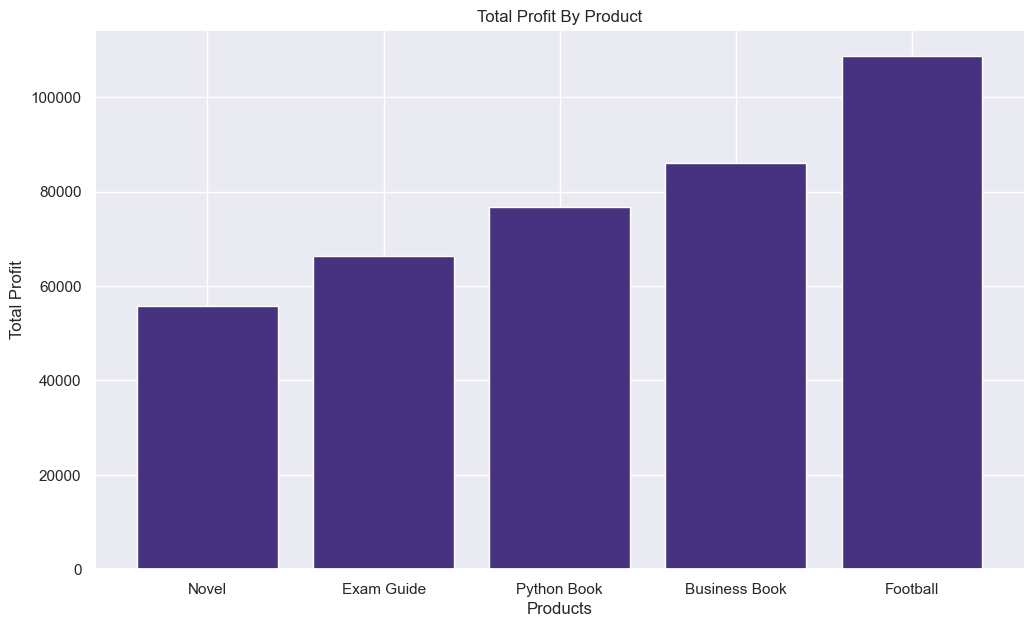

In [47]:
# Find the Bottom 5 Products by Total Profit and create a bar chart showing their Profit.

bottom_Products = df.groupby('Product')['Profit'].sum().sort_values(ascending=True).head(5)
# print(bottom_Products)

plt.figure(figsize=(12, 7))
plt.bar(bottom_Products.index , bottom_Products.values)
plt.ticklabel_format(style='plain', axis='y')

plt.xlabel('Products')
plt.ylabel('Total Profit')
plt.title('Total Profit By Product')

plt.show()

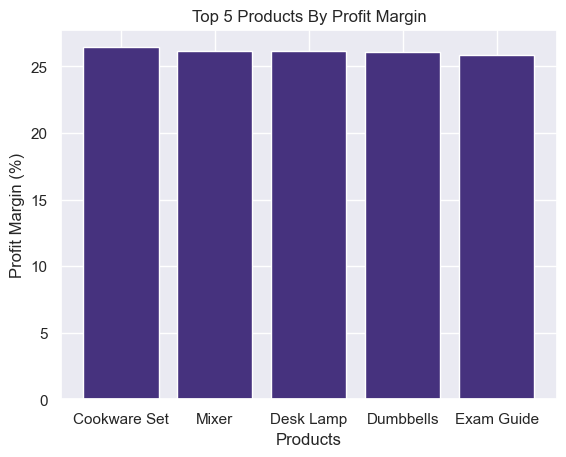

In [48]:
# Top 5 Products by Profit Margin

total_sales = df.groupby('Product')['Sales'].sum()
total_profit = df.groupby('Product')['Profit'].sum()

Profit_Margin = (total_profit / total_sales) * 100
top_five = (Profit_Margin).sort_values(ascending=False).head(5)
# print(top_five)

plt.bar(top_five.index , top_five.values)
plt.xlabel('Products')
plt.ylabel('Profit Margin (%)')
plt.title('Top 5 Products By Profit Margin')

plt.show()

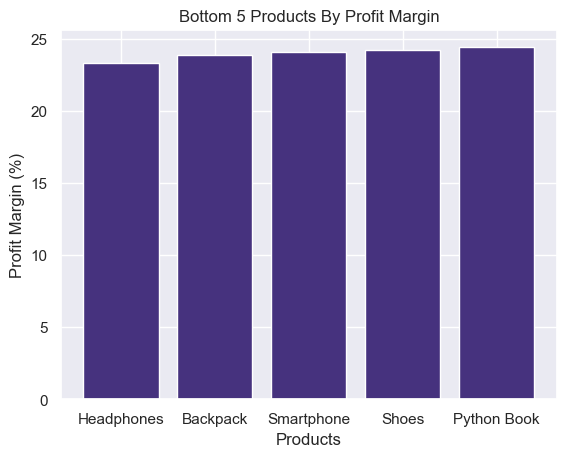

In [49]:
# Products with Lowest Profit Margin

total_sales = df.groupby('Product')['Sales'].sum()
total_profit = df.groupby('Product')['Profit'].sum()

Profit_Margin = (total_profit / total_sales) * 100
bottom = (Profit_Margin).sort_values(ascending=True).head(5)
# print(bottom)

plt.bar(bottom.index , bottom.values)
plt.xlabel('Products')
plt.ylabel('Profit Margin (%)')
plt.title('Bottom 5 Products By Profit Margin')

plt.show()

In [50]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'City', 'Region', 'Category',
       'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit',
       'Payment_Method', 'Sales_Channel', 'Customer_Type', 'Customer_Rating',
       'Shipping_Type', 'Month'],
      dtype='object')

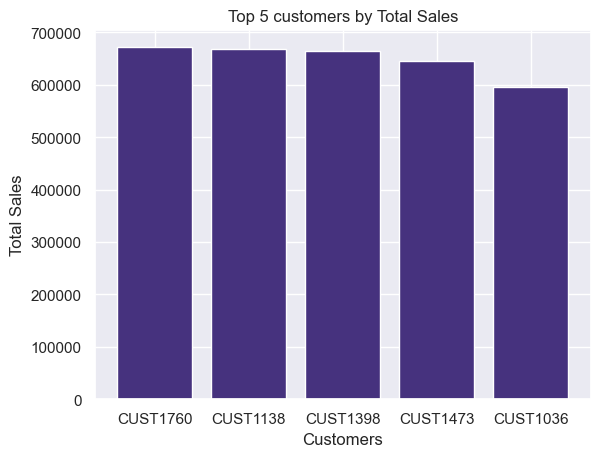

In [51]:
# Top 5 Customers by Total Sales

ans = df.groupby('Customer_ID')['Sales'].sum().sort_values(ascending=False).head(5)
ans

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Total Sales')
plt.title('Top 5 customers by Total Sales')

plt.show()

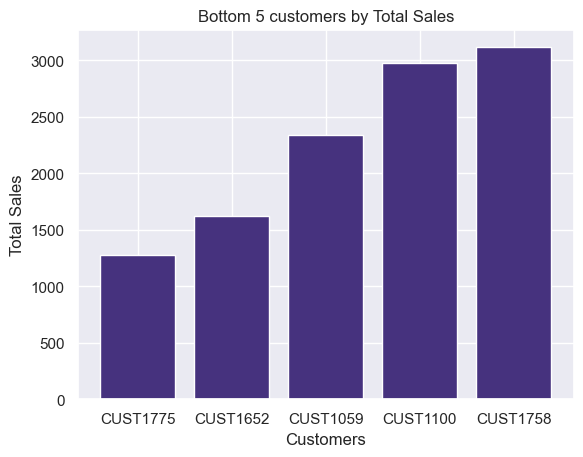

In [52]:
# Bottom 5 Customers by Total Sales

ans = df.groupby('Customer_ID')['Sales'].sum().sort_values().head(5)
ans

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Total Sales')
plt.title('Bottom 5 customers by Total Sales')

plt.show()

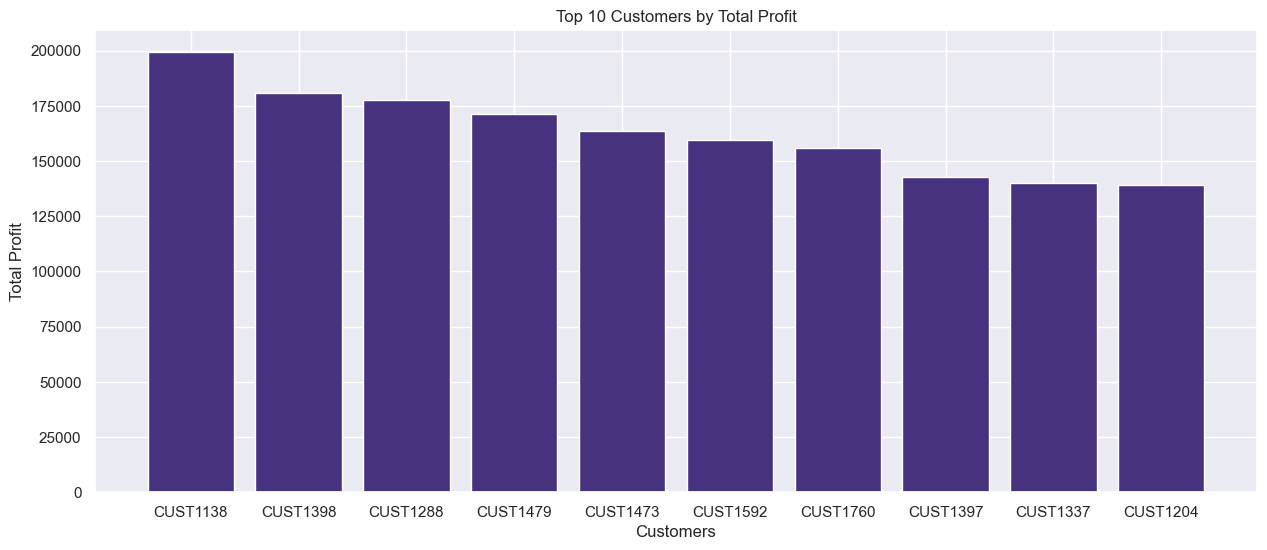

In [53]:
# Top 10 Customers by Total Profit

ans = df.groupby('Customer_ID')['Profit'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(15, 6))
plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Total Profit')
plt.title('Top 10 Customers by Total Profit')

plt.show()

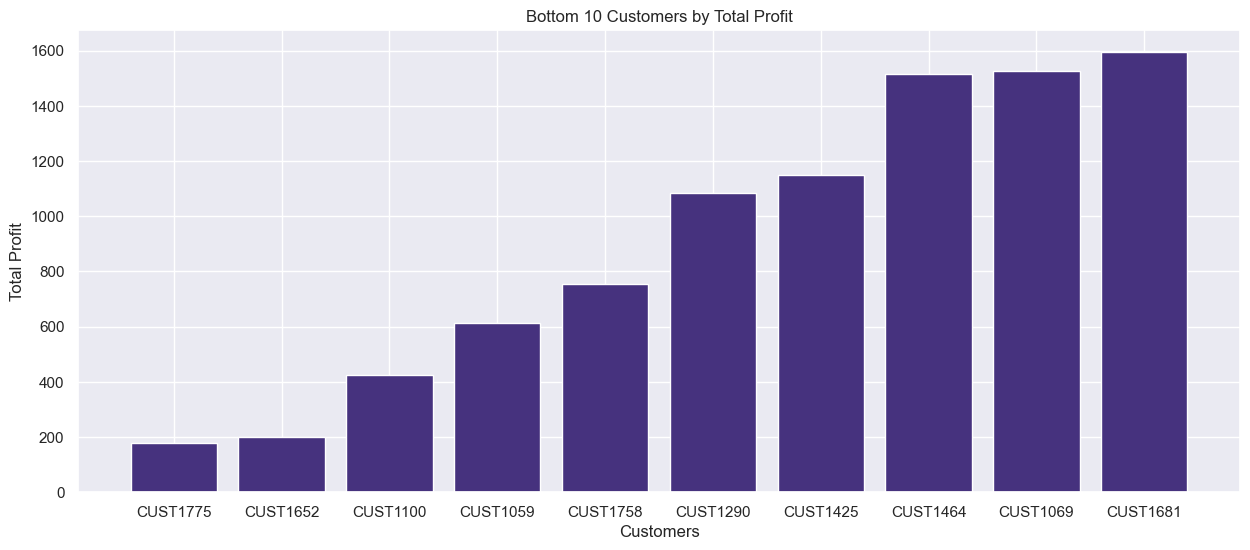

In [54]:
# Bottom 10 Customers by Total Profit

ans = df.groupby('Customer_ID')['Profit'].sum().sort_values().head(10)
plt.figure(figsize=(15, 6))
plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Total Profit')
plt.title('Bottom 10 Customers by Total Profit')

plt.show()

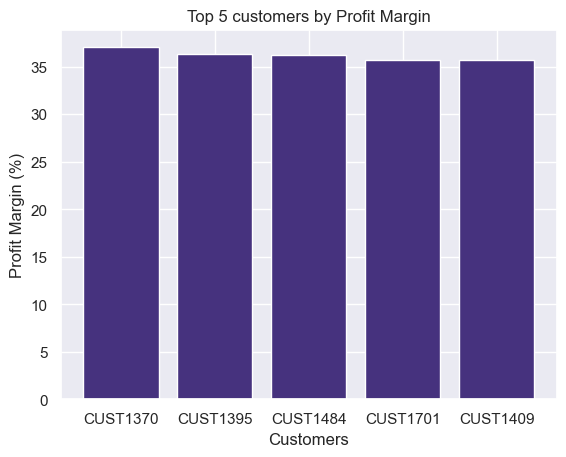

In [55]:
# Customer Profit Margin

total_sales = df.groupby('Customer_ID')['Sales'].sum()
total_profit = df.groupby('Customer_ID')['Profit'].sum()

Profit_Margin = (total_profit / total_sales) * 100
top_5 = Profit_Margin.sort_values(ascending=False).head(5)

plt.bar(top_5.index , top_5.values)
plt.xlabel('Customers')
plt.ylabel('Profit Margin (%)')
plt.title('Top 5 customers by Profit Margin')

plt.show()

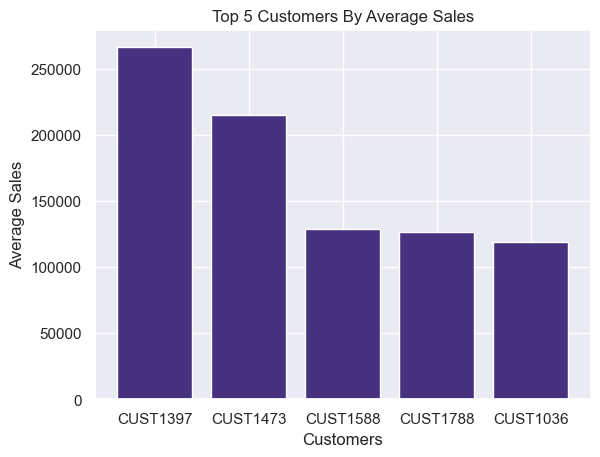

In [56]:
# Find the Top 5 Customers by Average Sales per Order and create a bar chart.

ans = df.groupby('Customer_ID')['Sales'].mean().sort_values(ascending=False).head(5)

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Average Sales')
plt.title('Top 5 Customers By Average Sales')

plt.show()

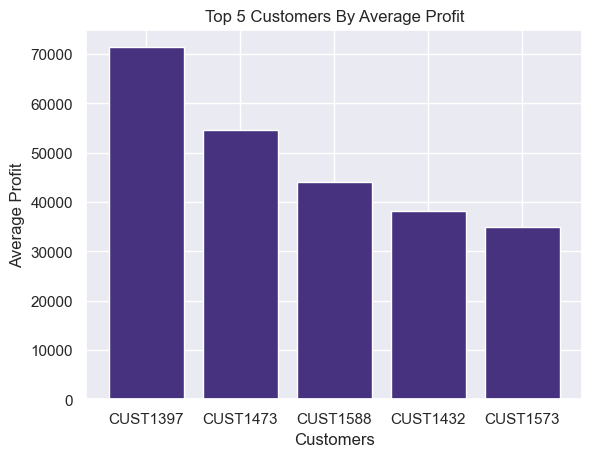

In [57]:
# Find the Top 5 Customers by Average Profit per Order and create a bar chart.

ans = df.groupby('Customer_ID')['Profit'].mean().sort_values(ascending=False).head(5)

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Average Profit')
plt.title('Top 5 Customers By Average Profit')

plt.show()

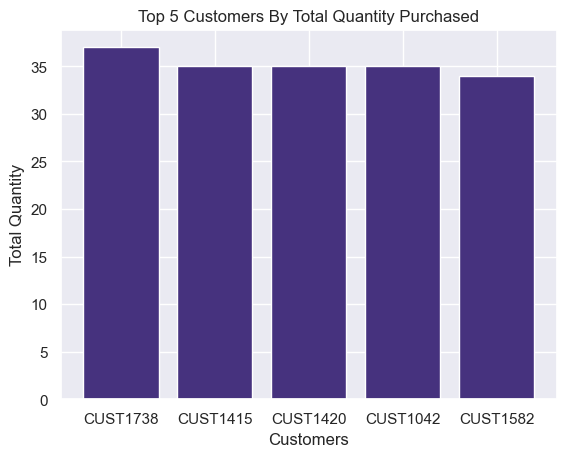

In [58]:
# Find the Top 5 Customers by Total Quantity Purchased and create a bar chart.

ans = df.groupby('Customer_ID')['Quantity'].sum().sort_values(ascending=False).head(5)

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Total Quantity')
plt.title('Top 5 Customers By Total Quantity Purchased')

plt.show()

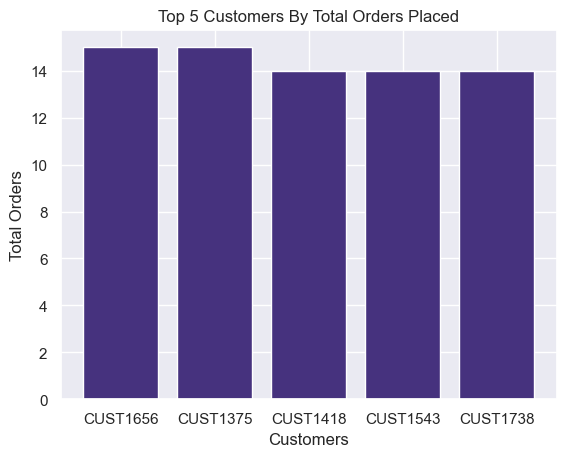

In [59]:
# Find the Top 5 Customers by Number of Orders and create a bar chart.

ans = df.groupby('Customer_ID')['Order_ID'].count().sort_values(ascending=False).head(5)

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Total Orders')
plt.title('Top 5 Customers By Total Orders Placed')

plt.show()

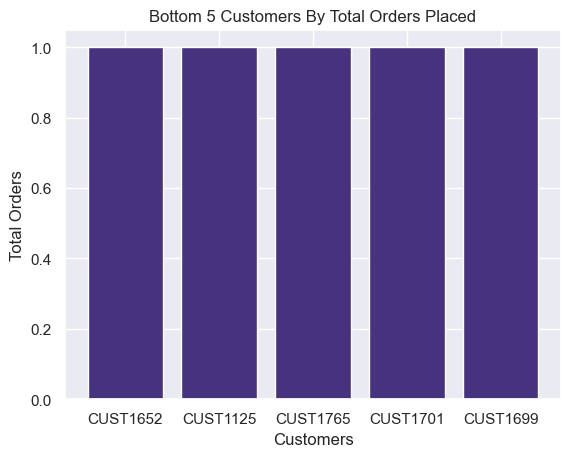

In [60]:
# Find the Bottom 5 Customers by Number of Orders and create a bar chart.

ans = df.groupby('Customer_ID')['Order_ID'].count().sort_values().head(5)

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Total Orders')
plt.title('Bottom 5 Customers By Total Orders Placed')

plt.show()

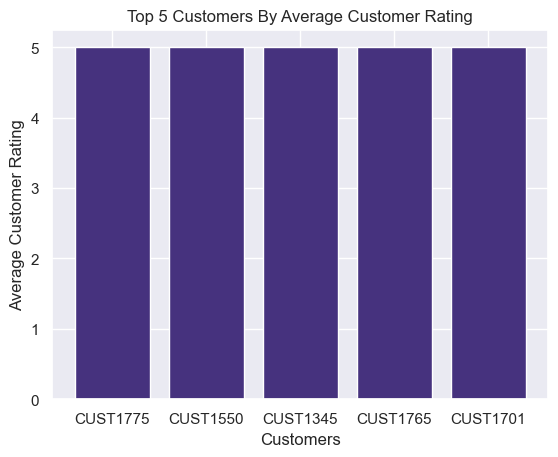

In [61]:
# Find the Top 5 Customers by Average Customer Rating and create a bar chart.

ans = df.groupby('Customer_ID')['Customer_Rating'].mean().sort_values(ascending=False).head(5)

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Average Customer Rating')
plt.title('Top 5 Customers By Average Customer Rating')

plt.show()

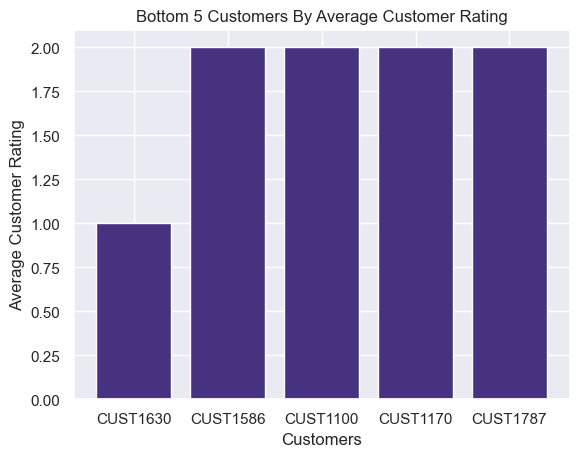

In [62]:
# Find the Bottom 5 Customers by Average Customer Rating and create a bar chart.

ans = df.groupby('Customer_ID')['Customer_Rating'].mean().sort_values(ascending=True).head(5)

plt.bar(ans.index , ans.values)
plt.xlabel('Customers')
plt.ylabel('Average Customer Rating')
plt.title('Bottom 5 Customers By Average Customer Rating')

plt.show()

In [80]:
# For each Region, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('Region')['Sales'].sum()
total_order = df.groupby('Region')['Order_ID'].count()
total_profit = df.groupby('Region')['Profit'].sum()
total_quantity = df.groupby('Region')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Region,,,,,
East,12184659.58,3026867.57,1192,23120.796167,24.841626
North,31981378.09,8162391.92,3446,21756.039517,25.522327
South,32524863.16,7903449.11,3395,21946.601323,24.299715
West,37648552.84,9215424.16,3527,25403.881808,24.477499


In [81]:
# For each Category, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('Category')['Sales'].sum()
total_order = df.groupby('Category')['Order_ID'].count()
total_profit = df.groupby('Category')['Profit'].sum()
total_quantity = df.groupby('Category')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Category,,,,,
Books,1601953.87,399418.40,1691,2130.257806,24.933202
Electronics,83740615.76,20604778.65,3150,63391.836306,24.605478
Fashion,6750032.51,1647991.77,2519,6204.073998,24.414575
Home & Kitchen,17517170.54,4459077.92,2472,16746.816960,25.455469
Sports,4729680.99,1196866.02,1728,6272.786459,25.305428


In [82]:
# For each Payment Method, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)


total_sales = df.groupby('Payment_Method')['Sales'].sum()
total_order = df.groupby('Payment_Method')['Order_ID'].count()
total_profit = df.groupby('Payment_Method')['Profit'].sum()
total_quantity = df.groupby('Payment_Method')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Payment_Method,,,,,
Cash on Delivery,23654432.45,5976474.40,2450,22210.734695,25.265770
Credit Card,26268671.64,6376393.63,2317,26750.174786,24.273757
Debit Card,22441734.27,5507916.57,2280,22876.385596,24.543186
Net Banking,20576745.78,5179342.77,2344,20911.327012,25.170855
UPI,21397869.53,5268005.39,2169,22547.807724,24.619299


In [83]:
# For each Shipping Type, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('Shipping_Type')['Sales'].sum()
total_order = df.groupby('Shipping_Type')['Order_ID'].count()
total_profit = df.groupby('Shipping_Type')['Profit'].sum()
total_quantity = df.groupby('Shipping_Type')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Shipping_Type,,,,,
Express,35006058.54,8556480.31,3346,24879.927889,24.442856
Same Day,9452696.02,2260682.86,1106,20026.898347,23.915747
Standard,69880699.11,17490969.59,7108,22673.815415,25.029758


In [84]:
# For each Sales Channel, 
# calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('Sales_Channel')['Sales'].sum()
total_order = df.groupby('Sales_Channel')['Order_ID'].count()
total_profit = df.groupby('Sales_Channel')['Profit'].sum()
total_quantity = df.groupby('Sales_Channel')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Sales_Channel,,,,,
Marketplace,39719821.30,9915967.22,3866,24308.336169,24.964783
Mobile App,38239866.69,9346284.10,3917,22761.825411,24.441205
Website,36379765.68,9045881.44,3777,22088.503752,24.865145


In [85]:
# For each Customer Type, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('Customer_Type')['Sales'].sum()
total_order = df.groupby('Customer_Type')['Order_ID'].count()
total_profit = df.groupby('Customer_Type')['Profit'].sum()
total_quantity = df.groupby('Customer_Type')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Customer_Type,,,,,
New,55584866.60,13731762.62,5534,23325.583970,24.704139
Returning,58754587.07,14576370.14,6026,22790.763022,24.808906


In [86]:
# For each Customer Rating, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('Customer_Rating')['Sales'].sum()
total_order = df.groupby('Customer_Rating')['Order_ID'].count()
total_profit = df.groupby('Customer_Rating')['Profit'].sum()
total_quantity = df.groupby('Customer_Rating')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Customer_Rating,,,,,
1.0,2380786.64,587313.03,314,17505.784118,24.668864
2.0,8922569.69,2194440.27,790,25348.209347,24.594263
3.0,16671648.45,4011161.36,1562,23782.665407,24.059777
4.0,42539317.18,10583580.39,4487,22144.360843,24.879526
5.0,43825131.71,10931637.71,4407,23676.462296,24.943765


In [87]:
# For each Product, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('Product')['Sales'].sum()
total_order = df.groupby('Product')['Order_ID'].count()
total_profit = df.groupby('Product')['Profit'].sum()
total_quantity = df.groupby('Product')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
Product,,,,,
Backpack,1190573.70,284350.08,491,5411.698636,23.883450
Business Book,336805.88,85984.65,341,2338.929722,25.529439
Cookware Set,3208212.40,848283.85,493,14386.602691,26.441013
Cricket Bat,1620737.12,408636.04,363,10593.053072,25.212975
Cycling Helmet,1174144.68,291684.94,339,7724.636053,24.842334
Data Analytics Book,468756.69,114696.66,364,2840.949636,24.468272
Desk Lamp,899487.00,235252.89,480,4612.753846,26.154118
Dumbbells,980699.10,255726.81,311,6671.422449,26.075971
Exam Guide,256874.13,66388.90,295,1808.972746,25.844915


In [88]:
# For each City, calculate:

# Total Sales
# Total Profit
# Total Quantity Sold
# Average Sales per Order
# Profit Margin (%)

total_sales = df.groupby('City')['Sales'].sum()
total_order = df.groupby('City')['Order_ID'].count()
total_profit = df.groupby('City')['Profit'].sum()
total_quantity = df.groupby('City')['Quantity'].sum()
average_sale = total_sales / total_order
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Total Quantity Sold': total_quantity,
    'Average Sales per Order': average_sale,
    'Profit Margin (%)': profit_margin
})

,Total Sales,Total Profit,Total Quantity Sold,Average Sales per Order,Profit Margin (%)
City,,,,,
Ahmedabad,11619586.30,2844450.35,1171,23665.145214,24.479790
Bengaluru,9705449.45,2276998.62,1092,20475.631751,23.461032
Chennai,11187933.28,2843959.35,1145,21682.041240,25.419881
Delhi,10807002.47,2838651.37,1123,21744.471771,26.266778
Hyderabad,11631480.43,2782491.14,1158,23641.220386,23.922072
Jaipur,11012825.04,2674235.12,1180,23785.799222,24.282917
Kolkata,12184659.58,3026867.57,1192,23120.796167,24.841626
Lucknow,10161550.58,2649505.43,1143,19924.608980,26.073830
Mumbai,12905891.31,3173736.00,1131,27576.690833,24.591374


In [89]:
# For each Region, calculate:

# Total Sales
# Total Profit
# Profit Margin (%)
# Number of Orders
# Average Profit per Order

total_sales = df.groupby('Region')['Sales'].sum()
total_order = df.groupby('Region')['Order_ID'].count()
total_profit = df.groupby('Region')['Profit'].sum()
profit_margin = total_profit / total_sales * 100
average_profit = total_profit / total_order


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Profit Margin (%)': profit_margin,
    'Number of Orders': total_order,
    'Average Profit per Order': average_profit,
    
})

,Total Sales,Total Profit,Profit Margin (%),Number of Orders,Average Profit per Order
Region,,,,,
East,12184659.58,3026867.57,24.841626,527,5743.581727
North,31981378.09,8162391.92,25.522327,1470,5552.647565
South,32524863.16,7903449.11,24.299715,1482,5332.961613
West,37648552.84,9215424.16,24.477499,1482,6218.234926


In [90]:
# For each Category, calculate:

# Total Sales
# Total Profit
# Number of Orders
# Average Sales per Order
# Average Profit per Order
# Profit Margin (%)

total_sales = df.groupby('Category')['Sales'].sum()
total_profit = df.groupby('Category')['Profit'].sum()
total_orders = df.groupby('Category')['Order_ID'].count()
average_sale = total_sales / total_orders
average_profit = total_profit / total_orders
profit_margin = total_profit / total_sales * 100


pd.DataFrame({
    'Total Sales': total_sales,
    'Total Profit': total_profit,
    'Number of Orders': total_orders,
    'Average Sales Per Order': average_sale,
    'Average Profit per Order': average_profit,
    'Profit Margin (%)': profit_margin
    
})

,Total Sales,Total Profit,Number of Orders,Average Sales Per Order,Average Profit per Order,Profit Margin (%)
Category,,,,,,
Books,1601953.87,399418.40,752,2130.257806,531.141489,24.933202
Electronics,83740615.76,20604778.65,1321,63391.836306,15597.864232,24.605478
Fashion,6750032.51,1647991.77,1088,6204.073998,1514.698318,24.414575
Home & Kitchen,17517170.54,4459077.92,1046,16746.816960,4262.980803,25.455469
Sports,4729680.99,1196866.02,754,6272.786459,1587.355464,25.305428


## Key Business Insights

- Insight 1 — Category Performance

Electronics is the best-performing category because it has the highest sales and highest profit. This shows that Electronics is an important category for the business.

- Insight 2 — Regional Performance

West region has the highest sales and profit, while East region has the lowest sales and profit. This shows that West is performing well, while East needs more attention.

- Insight 3 — Product Performance

Laptop is the top-selling product and has the highest sales. This shows that Laptop has strong demand and is an important product for the business.

- Insight 4 — Customer Type Performance

Returning customers generate higher total sales and profit than new customers. This shows that existing customers are important for the business and customer retention is useful.

- Insight 5 — Sales Channel Performance

Marketplace generates the highest sales and profit among all sales channels, while Website generates the lowest. This shows that Marketplace is performing better, while Website needs improvement.

- Insight 6 — Payment Method Performance

Credit Card generates the highest sales and profit among all payment methods, while Net Banking generates the lowest. This shows that Credit Card is an important payment method for the business.

- Insight 7 — Shipping Performance

Standard shipping generates the highest sales and profit among the shipping methods, while Same Day shipping generates the lowest. Standard shipping is an important shipping option for the business.

- Insight 8 — Customer Rating Performance

Customers with a rating of 5 generate the highest sales and profit, while customers with a rating of 1 generate the lowest. This shows that higher customer ratings are associated with better business performance.

- Insight 9 — Monthly Performance

May has the highest total sales and total profit, while July has the lowest total profit. This shows that business performance changes across months and weaker months need more attention.

- Insight 10 — Discount and Overall Performance

The 10% discount level has the highest total sales in the dataset. The 35% discount level has very low total sales, but this can also be because there are fewer orders at this discount level. So, discount performance should be checked using both sales and number of orders.

Overall, Electronics, Laptop, Marketplace, and West region are strong performers. East region, Website channel, and some low-performing products need more attention.

## Business Recommendations

1. The company should focus more on the Electronics category because it generates the highest sales and profit. Good stock levels and promotions can help increase sales further.

2. The company should focus more on the East region because it has the lowest sales and profit. More marketing, promotions, and customer engagement can help improve performance.

3. The company should focus on retaining existing customers because returning customers generate higher total sales and profit. Loyalty programs and personalized offers can help keep customers coming back.

4. The company should focus more on the Marketplace channel because it generates the highest sales and profit. The Website channel should be improved through better offers, promotions, and customer experience.

5. The company should maintain good stock and promotion for high-performing products like Laptop. Low-performing products should be reviewed to understand their low demand.

6. The company should continue supporting Credit Card payments because they generate the highest sales and profit. Standard shipping should also be maintained because it contributes the highest sales and profit among shipping methods.

7. The company should focus on improving customer satisfaction. Better product quality, customer service, and faster issue resolution can help improve customer ratings.

8. The company should study the reasons behind monthly changes in sales and profit. May performed very well, while July had the lowest profit. Marketing campaigns and offers can be planned for weaker months.

## Final Conclusion

This analysis helped us understand the overall performance of the e-commerce business by analyzing sales, profit, customers, products, regions, sales channels, payment methods, shipping methods, ratings, discounts, and monthly trends. Electronics and Laptop were the strongest performers, while West region and Marketplace also performed well. The analysis also identified areas that need improvement, such as the East region, Website channel, and low-performing products. These insights can help the company make better decisions for marketing, customer retention, product strategy, and business growth.